# Ill-conditioned inverse problem

In this notebook, we study a 2D ill-conditioned inverse problem by first formulating a perturbed linear system and then solving it via (i) classical regularisation techniques and (ii) a learned neural-network approach, comparing reconstruction accuracy and stability between the two methods.

##### Structure of the notebook
Here is an outline of this Jupyter notebook:
1. Importing the necessary libraries
2. Setting up the problem
3. Setting up the data
4. Approach based on classical regularisation
5. Approach based on a neural network

The notebook concludes with a brief summary of the obtained results.

### 1. Importing necessary libraries

In [1]:
from matplotlib.colors import hsv_to_rgb
import matplotlib.pyplot as plt
import numpy as np
import torch

### 2. Setting up the problem

In [2]:
eps = 0.25
A = torch.tensor([[1. + eps, 1.], [1., 1. + eps]])

$A$ is somewhat ill-conditioned as evidenced by the condition number (the ratio of the top and bottom singular value):

In [3]:
A_svd = torch.linalg.svd(A)
(A_svd.S.max() / A_svd.S.min()).item()

9.0

We are interested in recovering $\mathbf x$ from $\mathbf y^\delta$, with
$$ \mathbf y^\delta = A\mathbf x + \mathbf z,$$
where $\mathbf z$ is some additive noise. The inversion is made difficult by the combination of the conditioning of $A$ and the presence of noise.

We will further assume that $\mathbf x$ lies in a set which may be complicated to describe, but from which we can sample.

### 3. Setting up the data

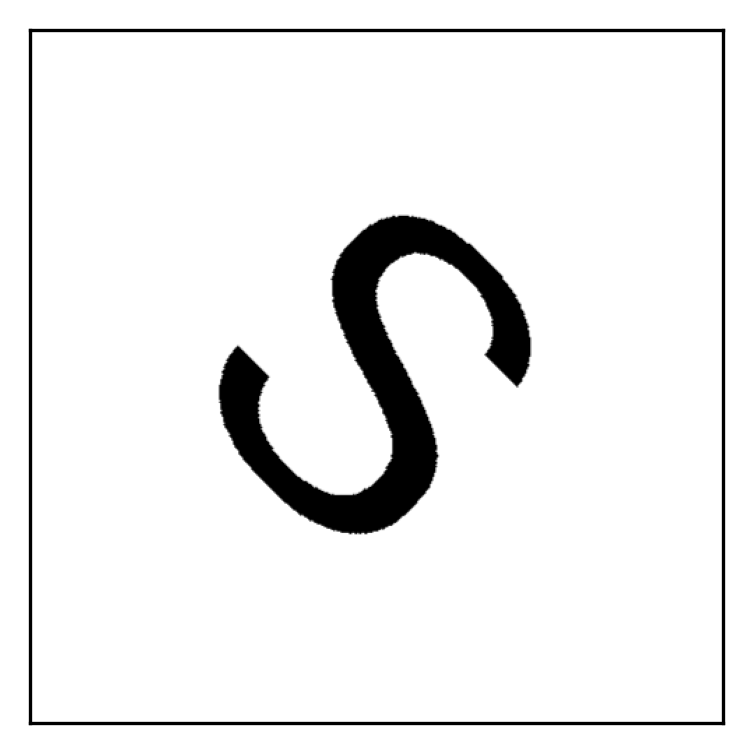

In [4]:
plt.rcParams["figure.figsize"] = (3, 3)

plt.rcParams["figure.dpi"] = 300
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 10

mask = np.load("data.npy")
plt.imshow(mask, aspect="equal", cmap="gray_r")
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)

In [5]:
N_train = 100
N_test = 1000
noise_level = 0.05

xs = []
while len(xs) < N_train:
    c_x, c_y = np.random.randint(495), np.random.randint(495)
    if mask[c_x, c_y] == 1.:
        xs.append([c_y, 495 - c_x])
xs_train = torch.tensor(xs) / 495 - 0.5
Axs_train = xs_train @ A.T
ys_train = Axs_train + noise_level * torch.randn_like(Axs_train)

xs = []
while len(xs) < N_test:
    c_x, c_y = np.random.randint(495), np.random.randint(495)
    if mask[c_x, c_y] == 1.:
        xs.append([c_y, 495 - c_x])
        
xs_test = torch.tensor(xs) / 495 - 0.5
Axs_test = xs_test @ A.T
ys_test = Axs_test + noise_level * torch.randn_like(Axs_test)

In [6]:
naive_recon_clean_train = Axs_train @ torch.linalg.inv(A).T
naive_recon_clean_test = Axs_test @ torch.linalg.inv(A).T

naive_recon_train = ys_train @ torch.linalg.inv(A).T
naive_recon_test = ys_test @ torch.linalg.inv(A).T

In [7]:
def generate_colours(inputs):
    """Generate RGB colours for a batch of 2-D inputs.

    Each row is interpreted as a complex number whose angle sets the hue
    and whose magnitude (normalised across the batch) sets the value.
    
    Parameters
    ----------
    inputs : torch.Tensor
        Shape (N, 2) tensor containing the real and imaginary parts.
    
    Returns
    -------
    torch.Tensor
        Shape (N, 3) tensor of RGB colours in the range [0, 1].
    """
    
    # Build complex view of the 2-D points
    inputs_complex = torch.complex(inputs[:, 0], inputs[:, 1])
    
    # Magnitude (value channel) and its global maximum for normalisation
    norms = inputs_complex.abs()
    max_val = norms.max()
    
    # Hue: angle of the complex number mapped to [0, 1]
    args = torch.atan2(inputs_complex.real, inputs_complex.imag)
    
    # Compute RGB values
    rgbs = torch.tensor(hsv_to_rgb(torch.stack(((args + torch.pi) / (2 * torch.pi), torch.ones_like(args), norms / max_val), dim=1)))
    
    return rgbs

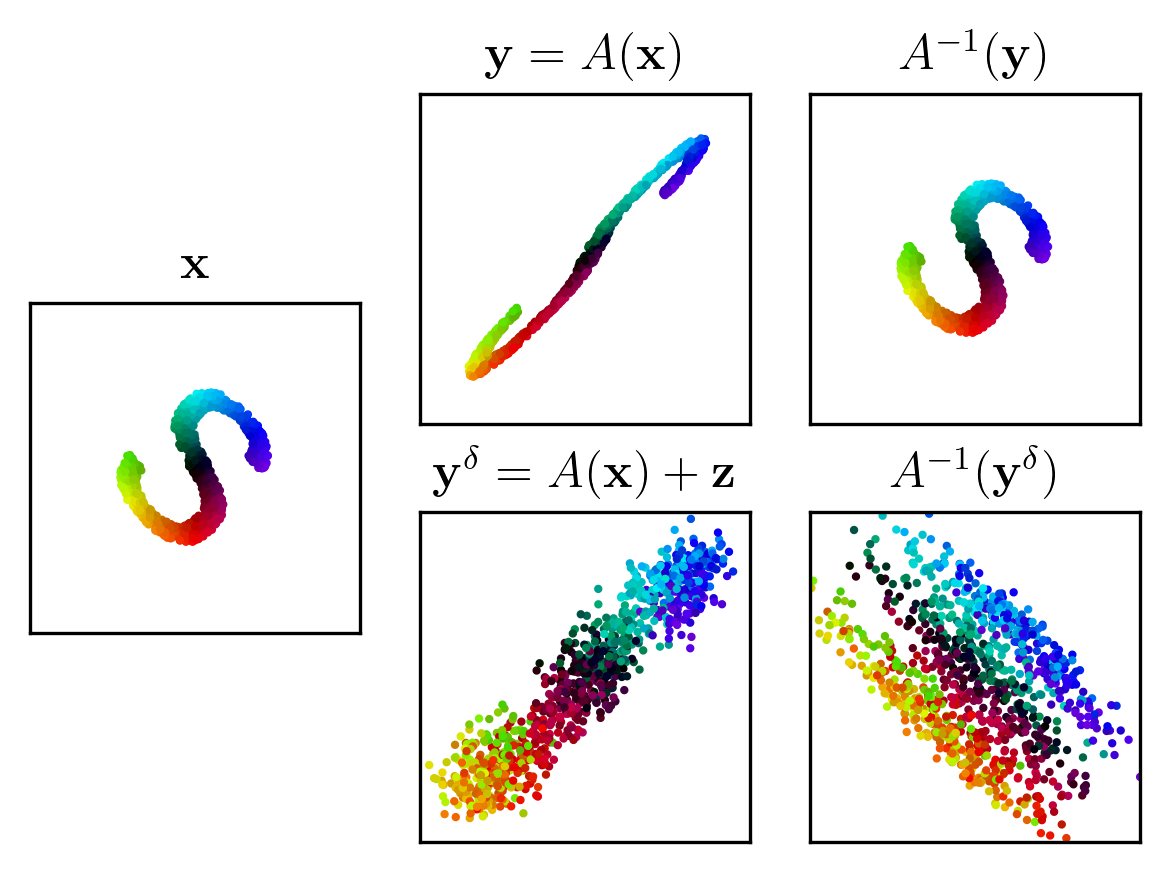

In [8]:
plt.rcParams["figure.figsize"] = (4, 3)

colours_train = generate_colours(xs_train)
colours_test = generate_colours(xs_test)

lim = 0.5

plt.subplot(1, 3, 1, aspect="equal")
plt.scatter(xs_test[:, 0], xs_test[:, 1], s=1, c=colours_test)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$\mathbf x$");

plt.subplot(2, 3, 2, aspect="equal")
plt.scatter(Axs_test[:, 0], Axs_test[:, 1], s=1, c=colours_test)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$\mathbf y = A(\mathbf x)$");

plt.subplot(2, 3, 3, aspect="equal")
plt.scatter(naive_recon_clean_test[:, 0], naive_recon_clean_test[:, 1], s=1, c=colours_test)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$A^{-1}(\mathbf y)$")

plt.subplot(2, 3, 5, aspect="equal")
plt.scatter(ys_test[:, 0], ys_test[:, 1], s=1, c=colours_test)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$\mathbf y^{\\mathbf \\delta} = A(\mathbf x) + \mathbf z$");

plt.subplot(2, 3, 6, aspect="equal")
plt.scatter(naive_recon_test[:, 0], naive_recon_test[:, 1], s=1, c=colours_test)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$A^{-1}(\mathbf y^{\\mathbf \\delta})$");

plt.tight_layout()
plt.savefig("ill_conditioned_inverse_problem.pdf")

### 4. Classical regularisation

One of the standard approaches to stabilising the inversion above is through Tikhonov regularisation (also known as ridge regression in the machine learning literature). Rather than directly invert, we consider the normal equation, perturb it slightly to make it more well-conditioned, and solve the perturbed equation:
$$
\hat{\mathbf x}_\tau = (A^\top A + \tau I)^{-1}A^\top \mathbf y^\delta,
$$
for some tunable $\tau > 0$. Larger $\tau$ corresponds to more stable inversion, but this comes at the cost of a bias. We can try to choose an optimal $\tau$ by using training data.

In [9]:
def tikhonov(A, ys, tau):
    """Return the ridge-regression / Tikhonov solution.

    Solves  (AᵀA + τI) x = Aᵀy  for x, minimising ‖Ax - y‖² + τ‖x‖².

    Parameters
    ----------
    A : torch.Tensor
        Design matrix of shape (m, n).
    ys : torch.Tensor
        Target tensor of shape (..., m).  Batch dims are allowed.
    tau : float | torch.Tensor
        Non-negative regularisation weight.

    Returns
    -------
    torch.Tensor
        Solution x of shape (..., n).
    """
    
    # Normal matrix with Tikhonov regularisation
    normal_matrix = A.T @ A + tau * torch.eye(A.shape[0])
    
    # Solve the linear system
    return (ys @ A) @ normal_matrix.inverse()

Our training set consists of the folowing data points (paired $\mathbf x$ and measurements $\mathbf y^\delta$):

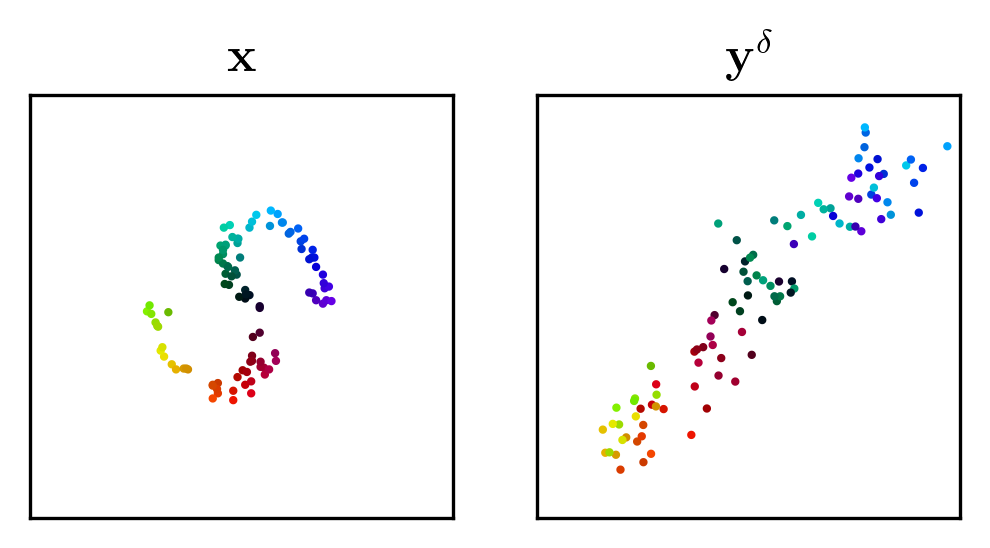

In [10]:
plt.subplot(1, 2, 1, aspect="equal")
plt.scatter(xs_train[:, 0], xs_train[:, 1], s=1, c=colours_train)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$\mathbf x$");

plt.subplot(1, 2, 2, aspect="equal")
plt.scatter(ys_train[:, 0], ys_train[:, 1], s=1, c=colours_train)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$\mathbf y^{\\delta}$");

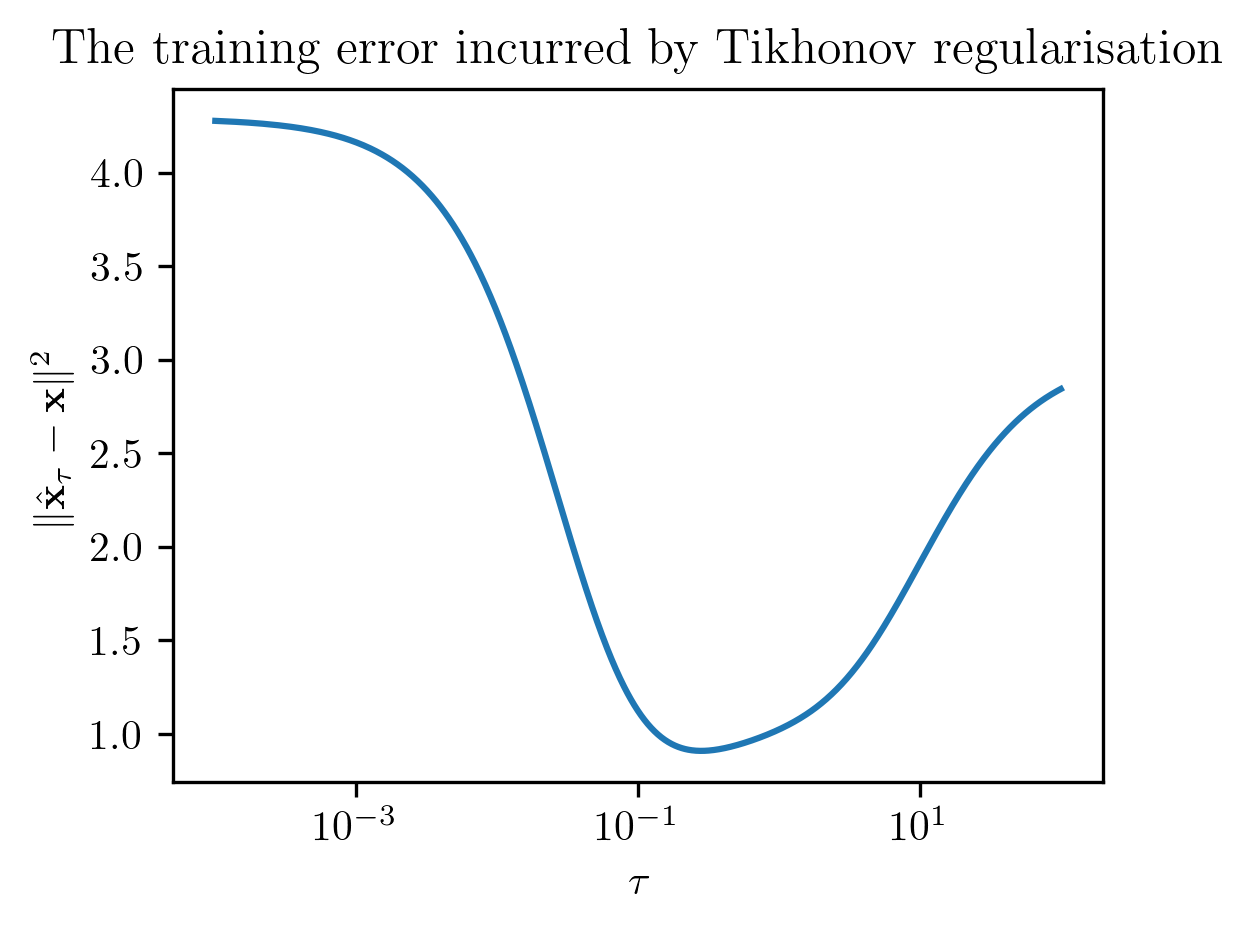

In [11]:
taus = torch.logspace(-4, 2, 1000)

sols = []
errors = []
for tau in taus:
    sols.append(tikhonov(A, ys_train, tau))
    errors.append((xs_train - sols[-1]).norm()**2)
    
plt.semilogx(taus, errors)
plt.xlabel("$\\tau$")
plt.ylabel("$\\| \\hat{\\mathbf x}_{\\tau} - \mathbf x \\|^2$")
plt.title("The training error incurred by Tikhonov regularisation");

The optimal choice of parameter $\tau^*$ stabilises the inversion well, but as we see below, it does not do particularly well at reconstructing the support of the true data:

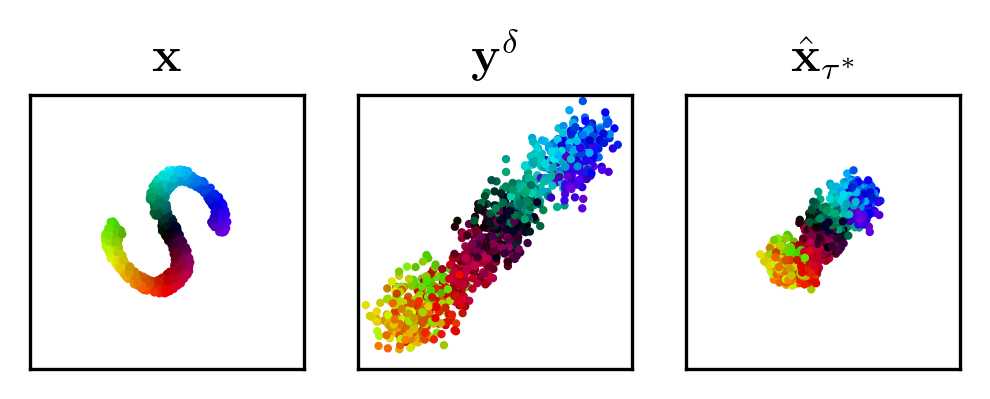

In [12]:
recons_tikhonov_test = tikhonov(A, ys_test, taus[np.argmin(errors)])

plt.subplot(1, 3, 1, aspect="equal")
plt.scatter(xs_test[:, 0], xs_test[:, 1], s=1, c=colours_test)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$\\mathbf x$");

plt.subplot(1, 3, 2, aspect="equal")
plt.scatter(ys_test[:, 0], ys_test[:, 1], s=1, c=colours_test)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$\mathbf y^{\\mathbf \\delta}$");

plt.subplot(1, 3, 3, aspect="equal")
plt.scatter(recons_tikhonov_test[:, 0], recons_tikhonov_test[:, 1], s=1, c=colours_test)
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
plt.title("$\\hat{\mathbf x}_{\\tau^*}$");

Given a value of $\tau$ and the singular value decomposition of $A$, it is easy for us to compute the (optimal) Lipschitz constant $L(\tau)$ of the Tikhonov regularisation approach, since it is a linear method:
$$
L(\tau) = \|(A^{\top}A + \tau I)^{-1}A^{\top}\| = \max_{i} \frac{\sigma_i}{\sigma_i^2 + \tau},
$$
with $\{\sigma_i\}_i$ the singular values of $A$. Clearly, $L$ is monotone decreasing, taking values between $1/(\min_i \sigma_i)$ and $0$.

In [13]:
def tikhonov_lipschitz_constant(A, tau):
    """Return the Lipschitz constant of the Tikhonov operator.

    For ridge-regularised regression the operator
        L = (AᵀA + τI)⁻¹ Aᵀ
    has Lipschitz constant  
        maxₖ σₖ / (σₖ² + τ),  
    where σₖ are the singular values of A.

    Parameters
    ----------
    A : torch.Tensor
        Design matrix of shape (m, n).
    tau : float | torch.Tensor
        Positive Tikhonov (ridge) parameter.

    Returns
    -------
    float
        The Lipschitz constant as a Python float.
    """
    
    # Singular values of A
    sigmas = torch.linalg.svd(A).S
    
    # Element-wise expression σ / (σ² + τ); take the maximum
    return (sigmas / (sigmas**2 + tau)).max().item()

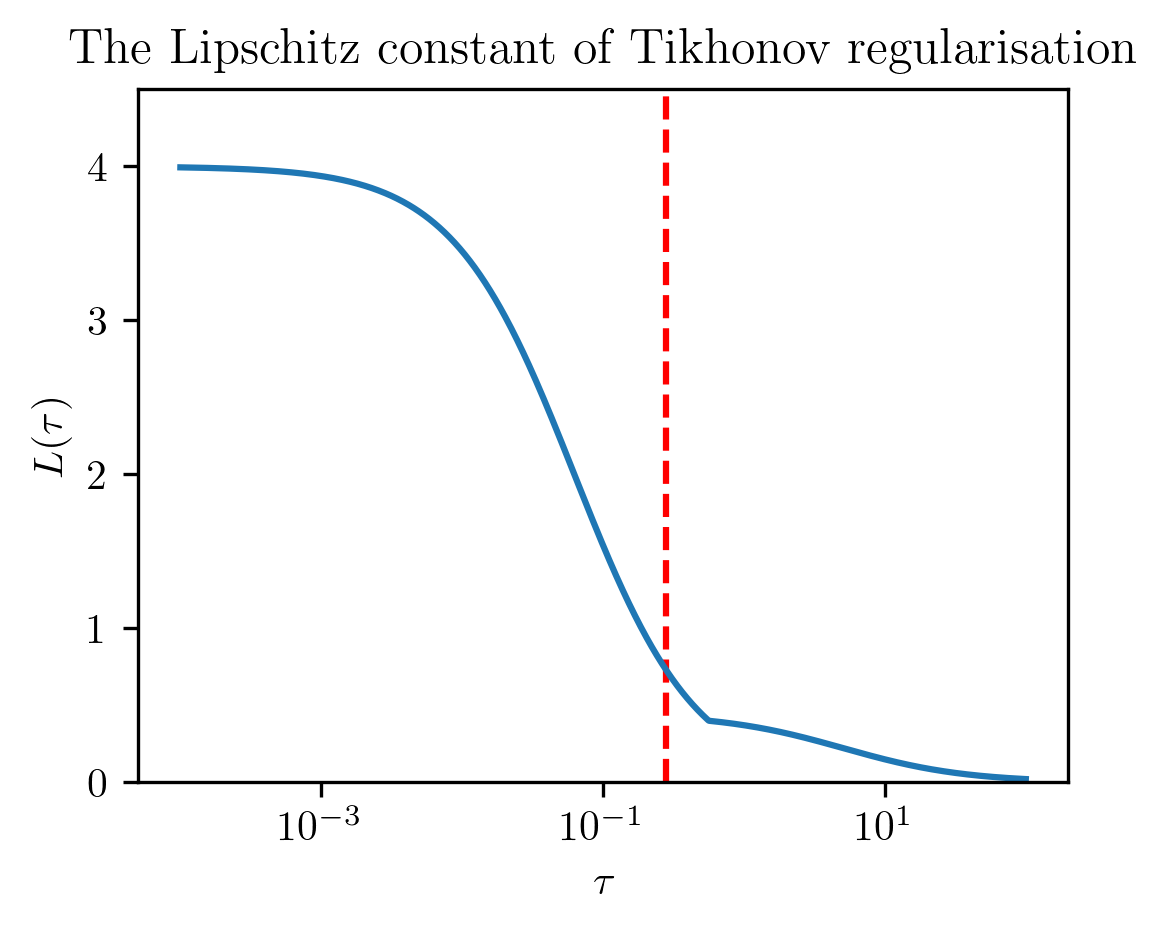

In [14]:
plt.semilogx(taus, [tikhonov_lipschitz_constant(A, tau) for tau in taus])
plt.vlines([taus[np.argmin(errors)]], 0, 5, linestyle='--', colors=['red'])
plt.ylim(0, 4.5)
plt.ylabel("$L(\\tau)$")
plt.xlabel("$\\tau$")
plt.title("The Lipschitz constant of Tikhonov regularisation");

In [15]:
L_optimal = tikhonov_lipschitz_constant(A, taus[np.argmin(errors)])

To get an idea of the behaviour of the method at different Lipschitz constants, we can invert the relationship between $L$ and $\tau$:

In [16]:
def tikhonov_bisect_L(A, L, lower=0, upper=1e4, tol=1e-8):
    """Find τ so that the Tikhonov operator's Lipschitz constant ≤L.

    Uses bisection on τ ∈ [lower, upper].  
    
    Parameters
    ----------
    A : torch.Tensor
        Design matrix of shape (m, n).
    L : float
        Target Lipschitz bound.
    lower, upper : float, optional
        Bracketing interval for τ (default 0 to 1e4).
    tol : float, optional
        Stop when interval width ≤ tol.

    Returns
    -------
    float
        Approximate τ such that tikhonov_lipschitz_constant(A, τ) ≤ L within tol.
    """
    
    # Standard bisection method
    while abs(lower - upper) > tol:
        mid = (lower + upper) / 2
        if tikhonov_lipschitz_constant(A, mid) > L:
            lower = mid
        else:
            upper = mid            
    return mid

In [17]:
is_single_ell = input(r"Type y to use a single L, any other key to use those in the chapter?")=='y'
if is_single_ell:
    ell = float(input(r"Type the value of L you want to use"))
    Ls = [ell]
else:
    Ls = [L_optimal/3, L_optimal, L_optimal*3]
taus = [tikhonov_bisect_L(A, L) for L in Ls]

Type y to use a single L, any other key to use those in the chapter?


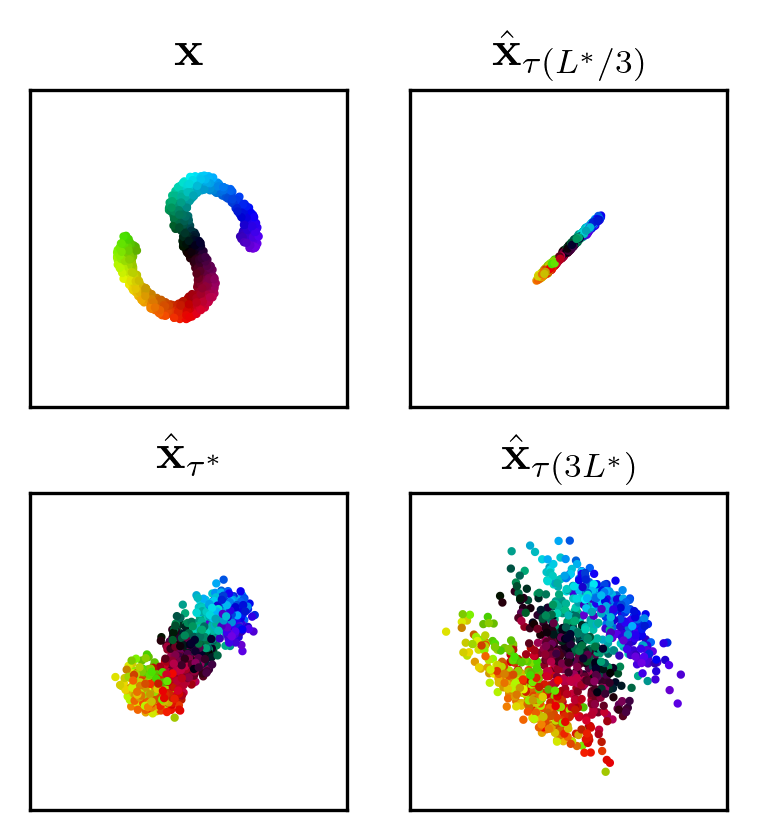

In [18]:
if not is_single_ell:
    plt.rcParams["figure.figsize"] = (3, 3.2)
    recons_tikhonov_test = [tikhonov(A, ys_test, tau) for tau in taus]

    plt.subplot(2, 2, 1, aspect="equal")
    plt.scatter(xs_test[:, 0], xs_test[:, 1], s=1, c=colours_test)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
    plt.title("$\\mathbf x$");

    plt.subplot(2, 2, 2, aspect="equal")
    plt.scatter(recons_tikhonov_test[0][:, 0], recons_tikhonov_test[0][:, 1], s=1, c=colours_test)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
    plt.title("$\\hat{\mathbf x}_{\\tau(L^*/3)}$");

    plt.subplot(2, 2, 3, aspect="equal")
    plt.scatter(recons_tikhonov_test[1][:, 0], recons_tikhonov_test[1][:, 1], s=1, c=colours_test)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
    plt.title("$\\hat{\mathbf x}_{\\tau^*}$");

    plt.subplot(2, 2, 4, aspect="equal")
    plt.scatter(recons_tikhonov_test[2][:, 0], recons_tikhonov_test[2][:, 1], s=1, c=colours_test)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
    plt.title("$\\hat{\mathbf x}_{\\tau(3L^*)}$");

### 5. A neural network approach

In [19]:
def power_method(linear, u_init=None, k=1):
    """Approximate the spectral norm of linear.weight via the power method.

    Parameters
    ----------
    linear : torch.nn.Linear
        Layer whose weight matrix A (shape: out_features x in_features) is
        analysed.
    u_init : torch.Tensor | None, optional
        Starting vector of length in_features.  If None (default) or wrong
        shape, a random unit vector is used instead.
    k : int, default 1
        Number of power-method iterations.

    Returns
    -------
    float
        Estimated largest singular value of A.
    torch.Tensor
        Final unit vector u (right singular vector estimate).
    """
    
    # Initial right-singular vector estimate
    if u_init is None or u_init.shape != linear.weight.shape[1:]:
        u_init = torch.randn(linear.weight.shape[1])
    u = u_init/u_init.norm()
    with torch.no_grad():
        for _ in range(k):
            u = u @ linear.weight.T @ linear.weight
            norm_ATAu = u.norm()
            u /= norm_ATAu
    
    # Spectral norm = √λ_max
    return norm_ATAu.sqrt().item(), u
    

In [20]:
from torch.nn.functional import relu

class NonExpansiveBlock(torch.nn.Module):
    """Residual block that performs a non-expansive Euler step.

    Repeatedly updates
        x ← x - (T / n_steps) · A^T ReLU(A x + b)
    where A is the linear layer's weight.

    Parameters
    ----------
    dim_inner : int, default 10
        Dimensionality of the input/state vector (in_features).
    dim_outer : int, default 10
        Dimensionality of the hidden activation (out_features).
    T : float, default 1.0
        Total step length, split equally across n_steps iterations.
    """
    
    def __init__(self, dim_inner=10, dim_outer=10, T=1.):
        super().__init__()
        self.lin = torch.nn.Linear(dim_inner, dim_outer)
        self.T = T
        
    def forward(self, x, n_steps):
        """Run n_steps of the explicit Euler method."""
        for i in range(n_steps):
            x = x - (self.T / n_steps) * relu(self.lin(x)) @ self.lin.weight
        return x

In [21]:
from math import ceil

class InvNet(torch.nn.Module):
    """L-Lipschitz network built from non-expansive residual blocks.

    f(x) = c · (Bₙ ○ … ○ B₁)(x̄),  where |c| ≤ L and x̄ is x zero-padded to
    dim_inner.  Each Bᵢ is a `NonExpansiveBlock`.

    Parameters
    ----------
    n_blocks : int, default 3
        Number of residual blocks.
    dim : int, default 2
        Input dimension.
    dim_inner : int, default 10
        Working/state dimension inside each block.
    dim_outer : int, default 10
        Hidden activation dimension in each block.
    L : float, default 1.0
        Desired global Lipschitz constant.
    """
    
    
    def __init__(self, n_blocks=3, dim=2, dim_inner=10, dim_outer=10, L=1.):
        super().__init__()
        self.L = L
        self.dim = dim
        self.dim_inner = dim_inner
        
        self.blocks = torch.nn.ModuleList([NonExpansiveBlock(dim_inner, dim_outer) for _ in range(n_blocks)])
        
        # Store power-method states for warm-starting
        self.singular_vectors = [None for _ in self.blocks]
        
        # Run many iterations of the power method at initialisation
        self.update_spectral_norms(k=10_000)
        self.c = torch.nn.Parameter(torch.tensor(1.))
        self.normalise()
        print("At initialisation of InvNet, we have the following c and operator norms:")
        print(self.c.item(), self.op_norms)
        
    def update_spectral_norms(self, k=1):
        """Refresh ‖Aᵢ‖₂ for each block using k power-method steps."""
        b_op_norms, b_singular_vectors = [], []
        for block, singular_vector in zip(self.blocks, self.singular_vectors):
            o, v = power_method(block.lin, u_init=singular_vector, k=k)
            b_op_norms.append(o)
            b_singular_vectors.append(v)
        self.op_norms, self.singular_vectors = b_op_norms, b_singular_vectors
        
    def normalise(self):
        """Clamp c so that |c| ≤ L (done in-place)."""
        torch.clamp_(self.c.data, -self.L, self.L)
    
    def forward(self, x):
        """Apply the network and return the first dim components."""
        z = torch.cat((x, torch.zeros(x.shape[0], self.dim_inner - self.dim)), dim=1)
        for i, block in enumerate(self.blocks):
            threshold = 2 / self.op_norms[i]**2
            n_steps = ceil(block.T / threshold)
            z = block(z, n_steps)
        return self.c * z[:, :self.dim]
            

In [22]:
models = {}
for L in Ls:
    models[L] = InvNet(n_blocks=10, L=L)

optimisers = {}
for L in Ls:
    optimisers[L] = torch.optim.Adam(models[L].parameters(), lr=1e-3)
losses = {L: [] for L in Ls}

At initialisation of InvNet, we have the following c and operator norms:
0.24317647516727448 [0.9097033739089966, 0.9263086318969727, 1.0017979145050049, 1.0221140384674072, 1.0257294178009033, 0.9901599884033203, 0.9392998218536377, 1.0207401514053345, 1.0344001054763794, 0.9114062786102295]
At initialisation of InvNet, we have the following c and operator norms:
0.7295294404029846 [1.036297082901001, 0.9315623044967651, 1.0378296375274658, 0.9668169617652893, 0.9309901595115662, 1.0457454919815063, 1.1149370670318604, 0.9668219685554504, 0.9744623899459839, 0.9621276259422302]
At initialisation of InvNet, we have the following c and operator norms:
1.0 [0.9853047132492065, 0.998835563659668, 0.986461877822876, 0.9906171560287476, 0.9428832530975342, 1.0527054071426392, 0.9601143002510071, 0.9373193383216858, 1.069990873336792, 0.9993008971214294]


In [23]:
n_iters = 10000

verbose = True #True to print out the loss through training, False otherwise

for i in range(n_iters):
    for L in Ls:
        optimisers[L].zero_grad()
        recon = models[L](ys_train)
        loss = torch.mean((recon - xs_train)**2)
        loss.backward()
        optimisers[L].step()
        models[L].update_spectral_norms()
        models[L].normalise()
        if i % 500 == 0 and verbose:
            print(f"Model L={L:.1f}: it {i} / {n_iters}, {loss.item():.2e}")
        losses[L].append(loss.item())

Model L=0.2: it 0 / 10000, 1.40e-02
Model L=0.7: it 0 / 10000, 2.45e-02
Model L=2.2: it 0 / 10000, 6.65e-02
Model L=0.2: it 500 / 10000, 6.87e-03
Model L=0.7: it 500 / 10000, 4.18e-03
Model L=2.2: it 500 / 10000, 4.00e-03
Model L=0.2: it 1000 / 10000, 6.82e-03
Model L=0.7: it 1000 / 10000, 3.82e-03
Model L=2.2: it 1000 / 10000, 3.54e-03
Model L=0.2: it 1500 / 10000, 6.82e-03
Model L=0.7: it 1500 / 10000, 3.63e-03
Model L=2.2: it 1500 / 10000, 3.17e-03
Model L=0.2: it 2000 / 10000, 6.82e-03
Model L=0.7: it 2000 / 10000, 3.55e-03
Model L=2.2: it 2000 / 10000, 2.91e-03
Model L=0.2: it 2500 / 10000, 6.82e-03
Model L=0.7: it 2500 / 10000, 3.49e-03
Model L=2.2: it 2500 / 10000, 2.77e-03
Model L=0.2: it 3000 / 10000, 6.81e-03
Model L=0.7: it 3000 / 10000, 3.42e-03
Model L=2.2: it 3000 / 10000, 2.69e-03
Model L=0.2: it 3500 / 10000, 6.81e-03
Model L=0.7: it 3500 / 10000, 3.40e-03
Model L=2.2: it 3500 / 10000, 2.54e-03
Model L=0.2: it 4000 / 10000, 6.80e-03
Model L=0.7: it 4000 / 10000, 3.37e-0

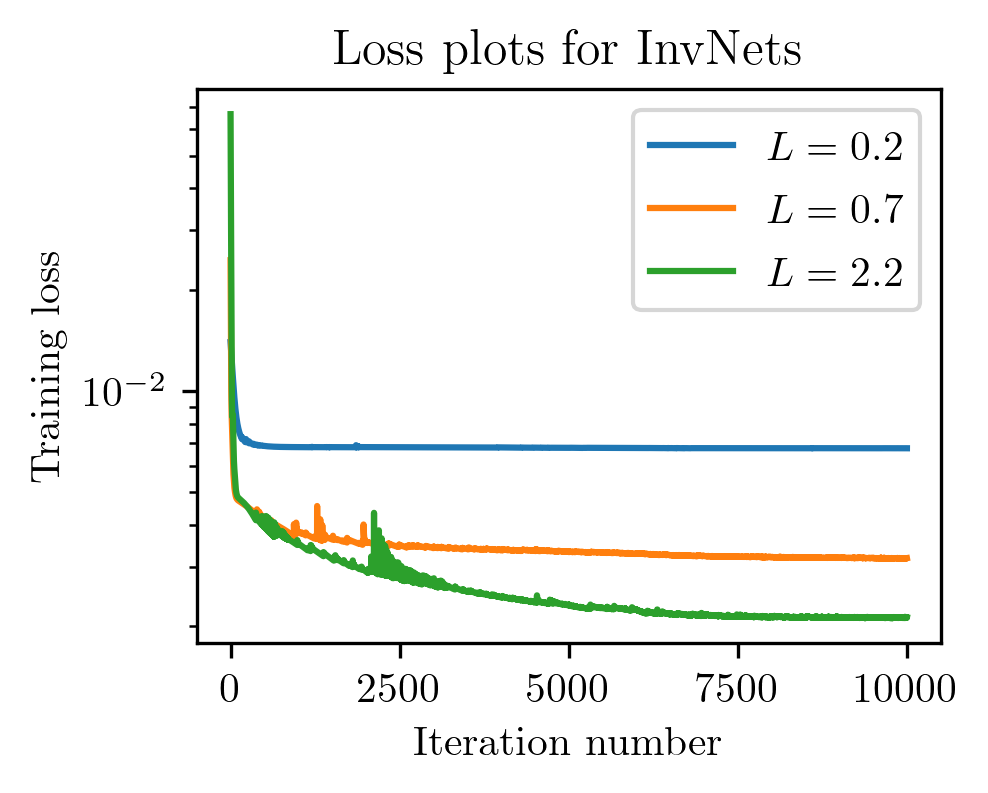

In [24]:
plt.rcParams["figure.figsize"] = (3.2, 2.4)
for i in range(len(Ls)):
    plt.semilogy(losses[Ls[i]])
plt.ylabel("Training loss")
plt.xlabel("Iteration number")
plt.legend([f"$L={Ls[i]:.1f}$" for i in range(len(Ls))])
plt.title("Loss plots for InvNets");

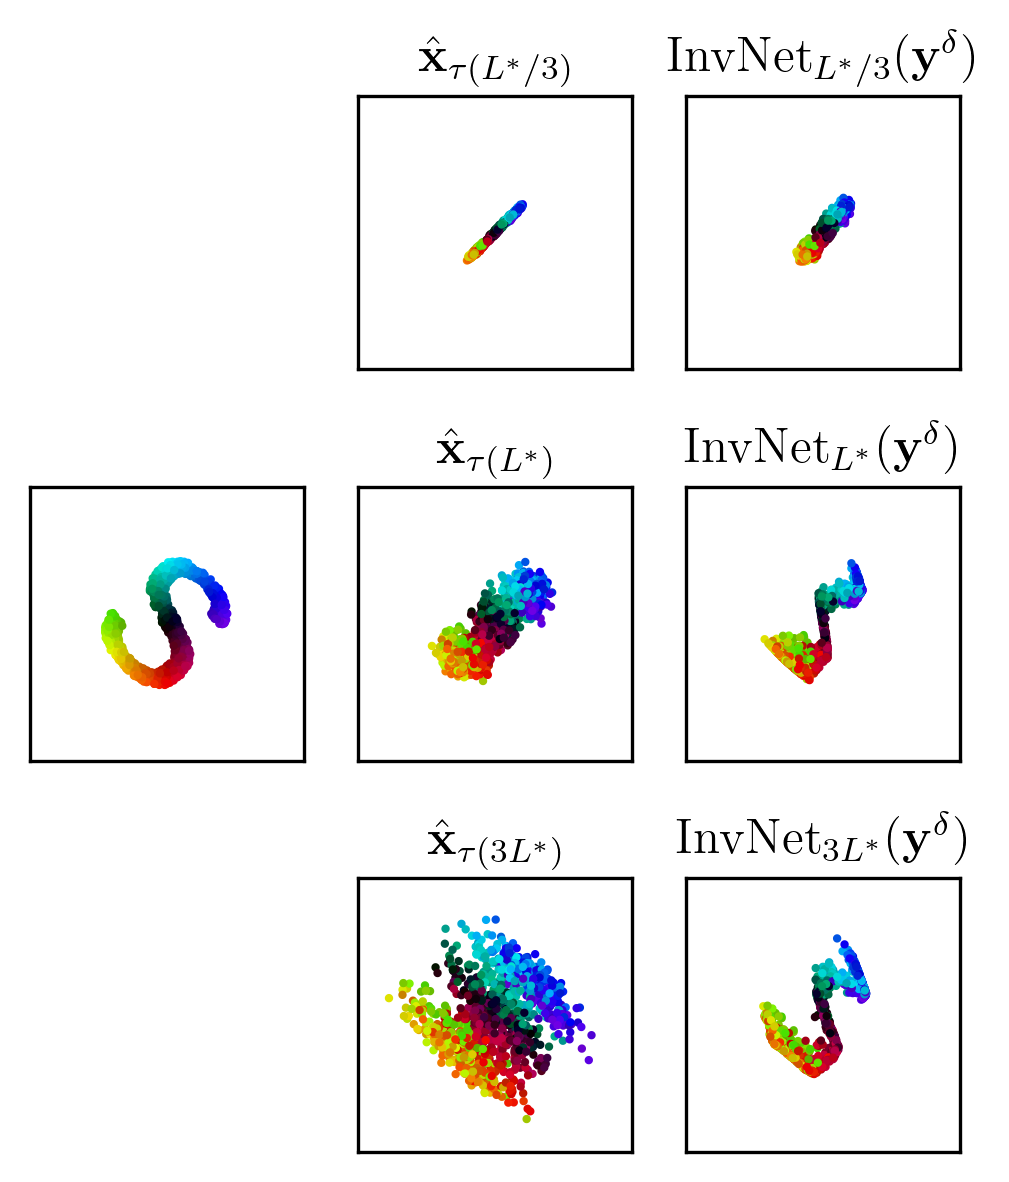

In [25]:
if not is_single_ell:
    plt.rcParams["figure.figsize"] = (4, 4.8)
    lim = 0.5

    plt.subplot(1, 3, 1, aspect="equal")
    plt.scatter(xs_test[:, 0], xs_test[:, 1], c=colours_test, s=1)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)


    invnet_recons = []
    tikhonov_recons = []

    for i, L in enumerate(Ls):
        with torch.no_grad():
            invnet_recons.append(models[L](ys_test))
            tikhonov_recons.append(tikhonov(A, ys_test, taus[i]))


    plt.subplot(3, 3, 2, aspect="equal")
    plt.scatter(tikhonov_recons[0][:, 0], tikhonov_recons[0][:, 1], c=colours_test, s=1)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.title("$\\hat{\mathbf x}_{\\tau(L^*/3)}$");
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)


    plt.subplot(3, 3, 3, aspect="equal")
    plt.scatter(invnet_recons[0][:, 0], invnet_recons[0][:, 1], c=colours_test, s=1)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.title("$\\mathrm{InvNet}_{L^*/3}(\mathbf y^{\\delta})$");
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)


    plt.subplot(3, 3, 5, aspect="equal")
    plt.scatter(tikhonov_recons[1][:, 0], tikhonov_recons[1][:, 1], c=colours_test, s=1)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.title("$\\hat{\mathbf x}_{\\tau(L^*)}$");
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)


    plt.subplot(3, 3, 6, aspect="equal")
    plt.scatter(invnet_recons[1][:, 0], invnet_recons[1][:, 1], c=colours_test, s=1)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.title("$\\mathrm{InvNet}_{L^*}(\mathbf y^{\\delta})$");
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
            
    plt.subplot(3, 3, 8, aspect="equal")
    plt.scatter(tikhonov_recons[2][:, 0], tikhonov_recons[2][:, 1], c=colours_test, s=1)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.title("$\\hat{\mathbf x}_{\\tau(3L^*)}$");
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)


    plt.subplot(3, 3, 9, aspect="equal")
    plt.scatter(invnet_recons[2][:, 0], invnet_recons[2][:, 1], c=colours_test, s=1)
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.title("$\\mathrm{InvNet}_{3L^*}(\mathbf y^{\\delta})$");
    plt.tick_params(labelbottom=False, labeltop=False, labelleft=False, labelright=False, bottom=False, top=False, left=False, right=False)
        

### **Conclusion and key takeaways**

1. **Problem set-up** – We posed a small **2-D linear inverse problem**: recover an unknown vector $\mathbf{x} \in\mathbb{R}^2$ from noisy measurements  
   $$
   \mathbf y^{\delta}=A\mathbf x+\mathbf z,
   $$
   where $A$ is moderately ill-conditioned (condition number $9$) and $\mathbf z$ is Gaussian.  
   We benchmarked two reconstruction strategies on the same train/test split:  
   - **Tikhonov regularisation** (linear, parameter $\tau$)  
   - **InvNet** – a learned neural inverse whose layers are 1-Lipschitz and whose **global Lipschitz constant is clamped to $L$**

2. **How this ties to the theory chapter** – The chapter shows  how to build Lipschitz-continuous networks, and this notebook demonstrates that they can be trained and provide a reliable approximation to the solution of a linear inverse problem. We compare two alternative strategies:
   - *Classical view*: choose $\tau$ so the **linear** Tikhonov map attains a target $L(\tau)$.  
   - *Learned view*: train InvNet, then **renormalise it after every update so its global $L$ matches the same budget**.  
   This lets us compare both methods under **identical stability levels**.

3. **Empirical observations**

When the Lipschitz constant of either the linear or neural approach is constrained to be lower than the optimal one $L^*$, they are both unable to recover a meaningful reconstruction of the input. Still, for a Lipschitz constant $L\geq L^*$, the Lipschitz-continuous network allows to recover a much more qualitative reconstruction than the linear approach.

4. **Main message** – **Learning the inverse map while keeping the *same* Lipschitz budget delivers much better accuracy than classical linear regularisation.**  

5. **Practical implication** – Being able to control the Lipschitz constant of a network allows for improved expressiveness and flexiblity than linear reconstruction, while still allowing to get the same stability guarantees of Tikhonov regularisation.
